# RetailPulse Data Analysis

## 1. Data Loading

In [54]:
import pandas as pd

df = pd.read_csv("../data/raw/superstore.csv", encoding="latin1")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [55]:
df.shape

(9994, 21)

In [56]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [57]:
df.head(3)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714


## 2. Data Cleaning

In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [59]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [60]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

## 3. Feature Engineering

In [61]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month_Name"] = df["Order Date"].dt.strftime("%b")

In [62]:
df["Profit_Margin"] = (df["Profit"] / df["Sales"]) * 100

## 4. Exploratory Data Analysis

In [63]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
aov = total_sales / total_orders

print("Total Sales:", total_sales)
print("Total Profit:", total_profit)
print("Total Orders:", total_orders)
print("Average Order Value:", aov)

Total Sales: 2297200.8603
Total Profit: 286397.0217
Total Orders: 5009
Average Order Value: 458.6146656618087


In [64]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
category_sales

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64

In [65]:
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)
category_profit

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64

In [66]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
region_sales

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64

In [67]:
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
top_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

In [68]:
df["Month_Num"] = df["Order Date"].dt.month

monthly_sales = (
    df.groupby(["Month_Num", "Month_Name"])["Sales"]
    .sum()
    .reset_index()
    .sort_values("Month_Num")
)

monthly_sales

,Month_Num,Month_Name,Sales
0,1,Jan,94924.8356
1,2,Feb,59751.2514
2,3,Mar,205005.4888
3,4,Apr,137762.1286
4,5,May,155028.8117
5,6,Jun,152718.6793
6,7,Jul,147238.0970
7,8,Aug,159044.0630
8,9,Sep,307649.9457
9,10,Oct,200322.9847


In [69]:
import matplotlib.pyplot as plt

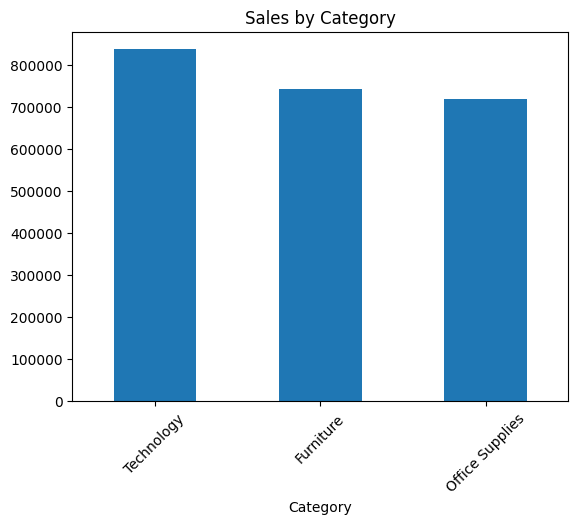

In [70]:
category_sales.plot(kind="bar")
plt.title("Sales by Category")
plt.xticks(rotation=45)
plt.show()

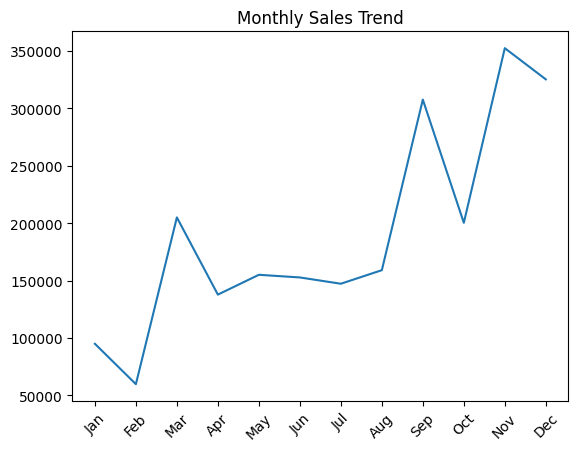

In [71]:
plt.plot(monthly_sales["Month_Name"], monthly_sales["Sales"])
plt.title("Monthly Sales Trend")
plt.xticks(rotation=45)
plt.show()

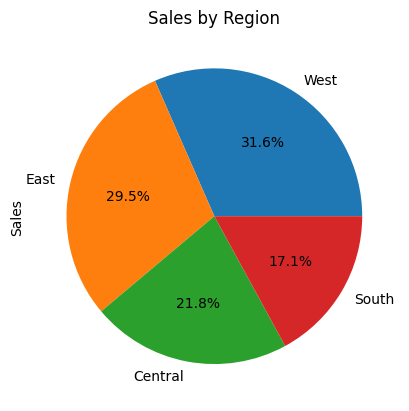

In [72]:
region_sales.plot(kind="pie", autopct="%1.1f%%")
plt.title("Sales by Region")
plt.show()

#INSIGHTS
1. Technology category generates the highest revenue.
2. Some categories show strong sales but weaker profit margins.
3. Western region contributes the most to total sales.
4. A small set of products drives a large share of revenue.
5. Sales show seasonal variation across months.

In [73]:
df.to_csv("../data/processed/cleaned_superstore.csv", index=False)
df.to_parquet("../data/processed/cleaned_superstore.parquet", index=False)

**SQL ANALYSIS**

## 5. SQL Analysis with DuckDB

In [74]:
import duckdb

In [75]:
query = """
SELECT * 
FROM read_parquet('../data/processed/cleaned_superstore.parquet')
LIMIT 5
"""

duckdb.sql(query).df()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month_Name,Profit_Margin,Month_Num
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,Nov,16.00,11
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,Nov,30.00,11
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,Jun,47.00,6
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,Oct,-40.00,10
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,Oct,11.25,10


In [76]:
query = """
SELECT SUM(Sales) AS Total_Sales
FROM read_parquet('../data/processed/cleaned_superstore.parquet')
"""

duckdb.sql(query).df()

,Total_Sales
0,2.297201e+06


In [77]:
query = """
SELECT SUM(Profit) AS Total_Profit
FROM read_parquet('../data/processed/cleaned_superstore.parquet')
"""

duckdb.sql(query).df()

,Total_Profit
0,286397.0217


In [78]:
query = """
SELECT Category, SUM(Sales) AS Total_Sales
FROM read_parquet('../data/processed/cleaned_superstore.parquet')
GROUP BY Category
ORDER BY Total_Sales DESC
"""

duckdb.sql(query).df()

,Category,Total_Sales
0,Technology,836154.0330
1,Furniture,741999.7953
2,Office Supplies,719047.0320


In [79]:
query = """
SELECT 
    month,
    SUM(Sales) AS revenue
FROM (
    SELECT 
        strftime("Order Date", '%Y-%m') AS month,
        Sales
    FROM read_parquet('../data/processed/cleaned_superstore.parquet')
)
GROUP BY month
ORDER BY month
"""

duckdb.sql(query).df()

,month,revenue
0,2014-01,14236.8950
1,2014-02,4519.8920
2,2014-03,55691.0090
3,2014-04,28295.3450
4,2014-05,23648.2870
5,2014-06,34595.1276
6,2014-07,33946.3930
7,2014-08,27909.4685
8,2014-09,81777.3508
9,2014-10,31453.3930


In [80]:
query = """
SELECT 
    "Customer ID",
    SUM(Sales) AS Total_Spent
FROM read_parquet('../data/processed/cleaned_superstore.parquet')
GROUP BY "Customer ID"
ORDER BY Total_Spent DESC
LIMIT 10
"""

duckdb.sql(query).df()

,Customer ID,Total_Spent
0,SM-20320,25043.050
1,TC-20980,19052.218
2,RB-19360,15117.339
3,TA-21385,14595.620
4,AB-10105,14473.571
5,KL-16645,14175.229
6,SC-20095,14142.334
7,HL-15040,12873.298
8,SE-20110,12209.438
9,CC-12370,12129.072


## 6. Python vs SQL Comparison

In [82]:
python_category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .reset_index()
    .sort_values("Sales", ascending=False)
)

python_category_sales

,Category,Sales
2,Technology,836154.0330
0,Furniture,741999.7953
1,Office Supplies,719047.0320


In [84]:
query = """
SELECT 
    Category,
    SUM(Sales) AS Sales
FROM read_parquet('../data/processed/cleaned_superstore.parquet')
GROUP BY Category
ORDER BY Sales DESC
"""

sql_category_sales = duckdb.sql(query).df()
sql_category_sales

,Category,Sales
0,Technology,836154.0330
1,Furniture,741999.7953
2,Office Supplies,719047.0320


In [85]:
print("Python result:")
print(python_category_sales)

print("\nSQL result:")
print(sql_category_sales)

Python result:
          Category        Sales
2       Technology  836154.0330
0        Furniture  741999.7953
1  Office Supplies  719047.0320

SQL result:
          Category        Sales
0       Technology  836154.0330
1        Furniture  741999.7953
2  Office Supplies  719047.0320


In [87]:
python_category_sales = python_category_sales.reset_index(drop=True)
sql_category_sales = sql_category_sales.reset_index(drop=True)

python_category_sales.equals(sql_category_sales)

False

In [88]:
python_monthly_sales = (
    df.groupby(df["Order Date"].dt.strftime("%Y-%m"))["Sales"]
    .sum()
    .reset_index()
)

python_monthly_sales.columns = ["month", "revenue"]
python_monthly_sales = python_monthly_sales.sort_values("month")
python_monthly_sales

,month,revenue
0,2014-01,14236.8950
1,2014-02,4519.8920
2,2014-03,55691.0090
3,2014-04,28295.3450
4,2014-05,23648.2870
5,2014-06,34595.1276
6,2014-07,33946.3930
7,2014-08,27909.4685
8,2014-09,81777.3508
9,2014-10,31453.3930


### Python vs SQL Summary

- Python was used for cleaning, date conversion, feature creation, and visualization.
- SQL was used for KPI queries, category-level sales summaries, and monthly revenue analysis.
- Results from Python and SQL were compared to validate analytical accuracy.